In [1]:
import pandas as pd, numpy as np

%load_ext autoreload
%autoreload 2

import hces_utils
from hces_utils import weighted_avg_and_std, weighted_summary

!date

Fri Nov 20 17:57:23 PST 2026


# HCES Data Extraction
We have HCES data to inform salt consumption for all household members in India, by sex, age group (0-5, 5-15, 15-30, 30-50, 50+)
and wealth quintile. HCES does not record pregnancy status, so pregnant women get the values for their sex, age group and quintile.

Old HCES data and documentation is saved on Sharepoint here: https://uwnetid.sharepoint.com/:f:/r/sites/ihme_simulation_science_team/Shared%20Documents/Research/LSFF/07_Data/HCES_22_data_files?csf=1&web=1&e=wmxQSD; new docs on HCES 2023-24 are stored in
`/snfs1/Project/simulation_science/IND_HOUSEHOLD_CONSUMPTION_EXPENDITURE_SURVEY_HCES_2023_2024/`

Item codes for 'Salt' include: 073, 178, and 170. See Section 5.3 of the above documentation for more context.
- Item code 178 signifies salt procured through PDS, using ration card.
- Item code 073 signifies salt procured through PDS, free of charge.
- Item code 170 signifies salt procured/consumed from other sources.

We also will need to approximate DHS wealth quintiles in the HCES data, by using similar variables as is used by the DHS to 
calculate wealth quintiles in India (see DHS wealth quintile documentation here: 
https://dhsprogram.com/programming/wealth%20index/India%20DHS%202015-16/India%202015-16%20sps.txt)

In this notebook, we extract the raw data from the HCES website and do some initial processing in order to create files 
that we can further tabulate based on our project needs in a later step. For now, we process these raw data into dataframes 
that have a row for each household/individual with the following columns:
- Whether or not salt was consumed (binary variable - this will be used to calculate coverage percentages later)
- Amount of salt consumed (grams per day - currently in raw HCES as kg/30 days for household) 
- Wealth composite score/quintile 
- Sex/gender (will be used to tabulate by sex)
- Age (will be used to tabulate age groups)



## Load data

In [2]:
households, household_members_raw = hces_utils.load_households()
households

,common_id,survey_name,year,fsu_serial_no,sector,state,nss_region,district,stratum,sub_stratum,...,bicycle,motorcycle,motor_car,trucks,animal_cart,refrigerator,washing_machine,air_conditioner,multichannel_tv_type,multiplier
0,HCES20242230023434102320110133231 101,HCES,2024,22300,urban,34,341,02,32,01,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,57436
1,HCES20242230023434102320110133231 201,HCES,2024,22300,urban,34,341,02,32,01,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,NaN,27497
2,HCES20242230023434102320110133231 202,HCES,2024,22300,urban,34,341,02,32,01,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,27497
3,HCES20242230023434102320110133231 203,HCES,2024,22300,urban,34,341,02,32,01,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,27497
4,HCES20242230023434102320110133231 204,HCES,2024,22300,urban,34,341,02,32,01,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,27497
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261948,HCES2024499991181840623135 118213 314,HCES,2024,49999,rural,18,184,06,23,13,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,79235
261949,HCES2024499991181840623135 118213 315,HCES,2024,49999,rural,18,184,06,23,13,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,79235
261950,HCES2024499991181840623135 118213 316,HCES,2024,49999,rural,18,184,06,23,13,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,79235
261951,HCES2024499991181840623135 118213 317,HCES,2024,49999,rural,18,184,06,23,13,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,79235


<Axes: >

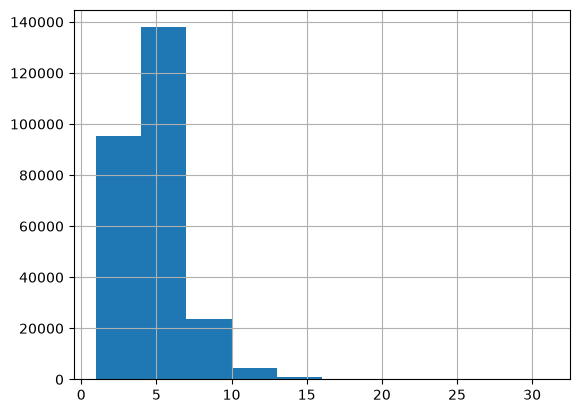

In [3]:
# The fact that there are a couple very large households (e.g. 20+ members) is a little
# surprising - maybe we can investigate to confirm these are some kind of GQ.
households.hh_size.hist()

In [4]:
# Bizarrely, I can't find documentation of these codes -- but we know the rent rate is only asked for rural
households.assign(rent_rate=households.rural_rent_rate_availability.notnull()).groupby(
    "sector"
).rent_rate.mean()

sector
rural    1.0
urban    0.0
Name: rent_rate, dtype: float64

In [5]:
households.sector.value_counts(dropna=False)

sector
rural    154357
urban    107596
Name: count, dtype: int64

In [6]:
households.isnull().mean().sort_values()

common_id              0.000000
survey_name            0.000000
year                   0.000000
fsu_serial_no          0.000000
sector                 0.000000
                         ...   
free_tablet            0.999313
free_laptop            0.999676
num_free_laptop        0.999676
num_free_motorcycle    0.999832
free_motorcycle        0.999832
Length: 111, dtype: float64

## Calculate wealth quintiles

In order to add wealth stratifications into our HCES data, we will emulate DHS methods for calculating wealth quintiles.
They don't ask something like "how wealthy are you?"
Instead, they ask "do you have a refrigerator?" and then a bunch of other questions like that,
and analyze them into a composite wealth index.
The way they do so is actually pretty weird and interesting, but I won't get into that here.
It is described at https://dhsprogram.com/topics/wealth-index/Wealth-Index-Construction.cfm.

In a first pass, we attempted to use the DHS weights directly.
See [this past version of the notebook](https://github.com/ihmeuw/vivarium_gates_lsff_2026_maternal/blob/12d63b4c5a3b7cb204c4f6eb3de7d6ffe87ce9c3/0100_data_prep/01_extract_hces.ipynb)
for how we started to do this.

However, this was tricky,
because none of the questions asked in HCES are exactly the same, with the same answer options,
as in DHS.
We could sort of use proxies and fudge things, but it was pretty rough.
Here, I have instead used the same *methods* used in the DHS to make an entirely new
model of the latent wealth variable.
I followed the steps described here: https://dhsprogram.com/programming/wealth%20index/Steps_to_constructing_the_new_DHS_Wealth_Index.pdf

However, even this is pretty underwhelming. Probably a better strategy to try in the future would be to make a more complex and
precise crosswalk between DHS and HCES questions/responses, then train a model in DHS to predict the DHS wealth quintile based
only on information available in HCES, and finally predict HCES.

DHS wealth index variables include: 
- Source of drinking water
- Type of toilet facility
- Electricity
- Mattress
- Pressure cooker
- Chair
- Cot or bed
- Table
- Electric fan
- Radio or transistor
- Black and white television
- Colour television
- Sewing machine
- Mobile telephone
- Telephone (non-mobile)
- Internet
- Computer
- Refrigerator
- Air conditioner/cooler
- Washing machine
- Watch or clock
- Bicycle
- Motorcycle or Scooter
- Animal-drawn cart
- Car
- Water pump
- Thresher
- Tractor
- Type of cooking fuel
- Main material of floor
- Main roof material
- Main wall material
- Hectares for agricultural land
- Out of this land, how much is irrigated?
- Cows / bulls / buffaloes
- Camels
- Horses / donkeys / mules
- Goats
- Sheep
- Chickens / ducks
- Bank account
- Members per sleeping room
- Compute urban and rural variables coded (1/0) for filters later
- Toilet facility by shared/not shared
- Land area by units - if there are separate units - need to convert them to one unit

HCES variables:
- Type of land owned
- What is the total area of all owned (owned and possessed or leased out) land (within the country) by the household as on the date of survey (area in acre)?(upto two places of decimal) 
- Primary source of energy of the household for cooking
- Any household member used the internet in the last 30 days (from the person-level level 2 records)
- Whether household possessed one or more item as on the date of the survey- Television 
- Whether household possessed one or more item as on the date of the survey- Radio
- Whether household possessed one or more item as on the date of the survey - Laptop/PC
- Whether household possessed one or more item as on the date of the survey- Mobile handset
- Whether household possessed one or more item as on the date of the survey- Bicycle
- Whether household possessed one or more item as on the date of the survey- Motorcycle, scooter 
- Whether household possessed one or more item as on the date of the survey- Motor car/jeep/van
- Whether household possessed one or more item as on the date of the survey- Trucks
- Whether household possessed one or more item as on the date of the survey - Animal cart
- Whether household possessed one or more item as on the date of the survey- Refrigerator
- Whether household possessed one or more item as on the date of the survey- Washing machine
- Whether household possessed one or more item as on the date of the survey- Air conditioner/air cooler 
- Type of multichannel television facility is used by the household as on the date of the survey

Crosswalk spreadsheet saved here: https://uwnetid.sharepoint.com/sites/ihme_simulation_science_team/_layouts/15/doc.aspx?sourcedoc={eddcbf51-3462-47d7-b847-79edea5046c6}&action=edit


In [7]:
wealth_info, wealth_predictors = hces_utils.assign_wealth_quintiles(
    households, diagnostics=True
)
wealth_info

national


,column,scores
20,cooking_energy_source_firewood,-0.387922
8,bicycle,-0.155764
2,house_ownership,-0.034361
24,cooking_energy_source_no cooking,-0.022112
18,cooking_energy_source_dung,-0.009245
25,cooking_energy_source_other,-0.008478
0,land_ownership,-0.004194
17,cooking_energy_source_coal,-0.003004
28,lighting_energy_source_candle,-0.002274
33,lighting_energy_source_other,-0.002146


urban


,column,scores
24,cooking_energy_source_no cooking,-0.094259
20,cooking_energy_source_firewood,-0.060470
17,cooking_energy_source_coal,-0.006667
25,cooking_energy_source_other,-0.004034
19,cooking_energy_source_electricity,-0.003030
32,lighting_energy_source_no lighting,-0.002320
18,cooking_energy_source_dung,-0.002262
22,cooking_energy_source_kerosene,-0.001987
33,lighting_energy_source_other,-0.001924
16,cooking_energy_source_charcoal,-0.001798


rural


,column,scores
20,cooking_energy_source_firewood,-0.481268
8,bicycle,-0.165160
25,cooking_energy_source_other,-0.008065
18,cooking_energy_source_dung,-0.006168
24,cooking_energy_source_no cooking,-0.005502
28,lighting_energy_source_candle,-0.002580
33,lighting_energy_source_other,-0.002382
32,lighting_energy_source_no lighting,-0.002082
31,lighting_energy_source_kerosene,-0.002075
2,house_ownership,-0.001261


urban
                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.864    
Dependent Variable: common_score     AIC:                9718.3376
Date:               2026-11-20 17:57 BIC:                9737.5099
No. Observations:   107596           Log-Likelihood:     -4857.2  
Df Model:           1                F-statistic:        6.820e+05
Df Residuals:       107594           Prob (F-statistic): 0.00     
R-squared:          0.864            Scale:              0.064083 
-------------------------------------------------------------------
                 Coef.   Std.Err.     t      P>|t|   [0.025  0.975]
-------------------------------------------------------------------
const            0.4544    0.0008  588.8195  0.0000  0.4529  0.4559
urban_score      0.8065    0.0010  825.8343  0.0000  0.8046  0.8085
------------------------------------------------------------------
Omnibus:             17309.248     Durbin-Watson:        1.137    
Pr

rural
                   Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.984       
Dependent Variable: common_score     AIC:                -262962.2122
Date:               2026-11-20 17:57 BIC:                -262942.3182
No. Observations:   154357           Log-Likelihood:     1.3148e+05  
Df Model:           1                F-statistic:        9.354e+06   
Df Residuals:       154355           Prob (F-statistic): 0.00        
R-squared:          0.984            Scale:              0.010658    
----------------------------------------------------------------------
                Coef.   Std.Err.      t       P>|t|    [0.025   0.975]
----------------------------------------------------------------------
const          -0.3168    0.0003  -1205.4818  0.0000  -0.3173  -0.3162
rural_score     0.9718    0.0003   3058.3798  0.0000   0.9712   0.9724
---------------------------------------------------------------------
Omnibus:             9228.92

,sector,hh_size,multiplier,land_ownership,has_dwelling,house_ownership,internet,tv,radio,laptop,...,lighting_energy_source_kerosene,lighting_energy_source_no lighting,lighting_energy_source_other,lighting_energy_source_other oil,common_score,urban_score,rural_score,combined_score,weighted_household_size,wealth_quintile
0,urban,4,57436,1.0,1.0,True,1.0,1.0,0.0,0.0,...,False,False,False,False,1.326677,1.105505,NaN,1.346056,229744,5
1,urban,4,27497,1.0,1.0,False,1.0,0.0,0.0,1.0,...,False,False,False,False,1.113051,0.670839,NaN,0.995478,109988,5
2,urban,2,27497,1.0,1.0,True,1.0,1.0,0.0,0.0,...,False,False,False,False,1.326677,1.105505,NaN,1.346056,54994,5
3,urban,2,27497,1.0,1.0,True,0.0,1.0,0.0,0.0,...,False,False,False,False,1.171171,1.001759,NaN,1.262380,54994,5
4,urban,2,27497,1.0,1.0,True,1.0,1.0,0.0,0.0,...,False,False,False,False,1.326677,1.105505,NaN,1.346056,54994,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261948,rural,6,79235,1.0,1.0,True,1.0,0.0,0.0,0.0,...,False,False,False,False,-1.447641,NaN,-1.177474,-1.461025,475410,1
261949,rural,4,79235,1.0,1.0,True,0.0,0.0,0.0,0.0,...,False,False,False,False,-1.603147,NaN,-1.338909,-1.617907,316940,1
261950,rural,7,79235,1.0,1.0,True,1.0,1.0,0.0,0.0,...,False,False,False,False,-1.099317,NaN,-0.808167,-1.102133,554645,1
261951,rural,11,79235,1.0,1.0,True,1.0,1.0,0.0,0.0,...,False,False,False,False,-0.774966,NaN,-0.470507,-0.773995,871585,2


<Axes: >

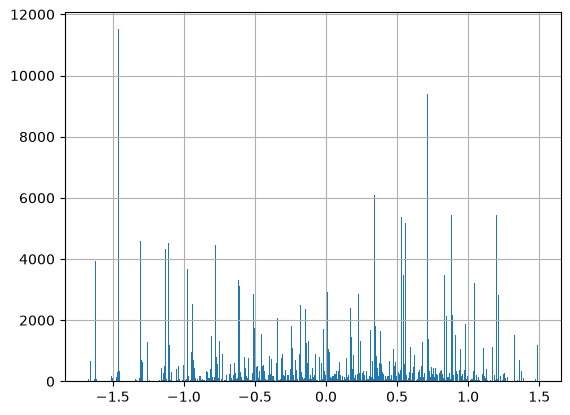

In [8]:
wealth_info.combined_score.hist(bins=500)

In [9]:
wealth_info.groupby(
    "wealth_quintile", observed=True
).multiplier.sum() / wealth_info.multiplier.sum()

wealth_quintile
1    0.214717
2    0.205948
3    0.212930
4    0.176727
5    0.189679
Name: multiplier, dtype: float64

In [10]:
for column in wealth_predictors:
    print(column)
    print(
        wealth_info.groupby(
            ["wealth_quintile", column], observed=True
        ).multiplier.sum()
        / wealth_info.groupby("wealth_quintile").multiplier.sum()
    )

land_ownership
wealth_quintile  land_ownership
1                0.0               0.072424
                 1.0               0.927576
2                0.0               0.110031
                 1.0               0.889969
3                0.0               0.080117
                 1.0               0.919883
4                0.0               0.057157
                 1.0               0.942843
5                0.0               0.030501
                 1.0               0.969499
Name: multiplier, dtype: float64
has_dwelling
wealth_quintile  has_dwelling
1                0.0             0.019929
                 1.0             0.980071
2                0.0             0.010203
                 1.0             0.989797
3                0.0             0.001794
                 1.0             0.998206
4                0.0             0.000574
                 1.0             0.999426
5                0.0             0.000409
                 1.0             0.999591
Name: multiplier,

wealth_quintile  animal_cart
1                0.0            0.997362
                 1.0            0.002638
2                0.0            0.994497
                 1.0            0.005503
3                0.0            0.993605
                 1.0            0.006395
4                0.0            0.987319
                 1.0            0.012681
5                0.0            0.990028
                 1.0            0.009972
Name: multiplier, dtype: float64
refrigerator
wealth_quintile  refrigerator
1                0.0             0.992843
                 1.0             0.007157
2                0.0             0.806549
                 1.0             0.193451
3                0.0             0.674585
                 1.0             0.325415
4                0.0             0.152539
                 1.0             0.847461
5                0.0             0.003987
                 1.0             0.996013
Name: multiplier, dtype: float64
washing_machine
wealth_quintile 

wealth_quintile  cooking_energy_source_gobar
1                False                          0.999959
                 True                           0.000041
2                False                          0.999325
                 True                           0.000675
3                False                          0.998753
                 True                           0.001247
4                False                          0.999523
                 True                           0.000477
5                False                          0.999923
                 True                           0.000077
Name: multiplier, dtype: float64
cooking_energy_source_kerosene
wealth_quintile  cooking_energy_source_kerosene
1                False                             0.999818
                 True                              0.000182
2                False                             0.998616
                 True                              0.001384
3                False           

wealth_quintile  lighting_energy_source_gas
1                False                         1.000000
2                False                         0.999992
                 True                          0.000008
3                False                         1.000000
4                False                         0.999995
                 True                          0.000005
5                False                         1.000000
Name: multiplier, dtype: float64
lighting_energy_source_kerosene
wealth_quintile  lighting_energy_source_kerosene
1                False                              0.996643
                 True                               0.003357
2                False                              0.999729
                 True                               0.000271
3                False                              0.999963
                 True                               0.000037
4                False                              0.999972
                 True  

In [11]:
# Whoa, owning land or a house is uncorrelated?!
india_dhs = pd.read_stata(
    "/snfs1/DATA/DHS_PROG_DHS/IND/2015_2016/IND_DHS7_2015_2016_HH_IAHR74FL_Y2018M12D06.DTA",
    columns=["hv005", "hv270", "sh46"],
).rename(columns={"hv005": "weight", "hv270": "wealth_quintile", "sh46": "owns_house"})

In [12]:
india_dhs.groupby(
    ["wealth_quintile", "owns_house"], observed=True
).weight.sum() / india_dhs.groupby("wealth_quintile").weight.sum()

wealth_quintile  owns_house
poorest          no            0.174830
                 yes           0.825170
poorer           no            0.179612
                 yes           0.820388
middle           no            0.213271
                 yes           0.786729
richer           no            0.248677
                 yes           0.751323
richest          no            0.191180
                 yes           0.808820
Name: weight, dtype: float64

In [13]:
# Bizarre. Even in DHS it's basically uncorrelated, although in HCES it seems to be reversed.

In [14]:
households["wealth_quintile"] = wealth_info["wealth_quintile"]

In [15]:
assert households.wealth_quintile.notnull().all()

## Household salt consumption

Item codes for 'Salt' include: 073, 178, and 170. See Section 5.3 of the above documentation for more context.

- Item code 178 signifies salt procured through PDS, using ration card.
- Item code 073 signifies salt procured through PDS, free of charge.
- Item code 170 signifies salt procured/consumed from other sources.

Units: kg/30 days.

In [16]:
consumption = hces_utils.read_consumption([73, 170, 178])
consumption

,common_id,q_num,level,item_code,consumption_amt_home_produce,consumption_value_home_produce,total_consumption_amt,total_consumption_value,source,multiplier
0,HCES2024466671010120613012 201103 201,F,5,170,NaN,NaN,1.20,34.0,1.0,16669
1,HCES2024466671010120613012 201103 301,F,5,170,NaN,NaN,0.80,23.0,1.0,24840
2,HCES2024466671010120613012 201103 302,F,5,170,NaN,NaN,1.00,28.0,1.0,24840
3,HCES2024466671010120613012 201103 303,F,5,170,NaN,NaN,1.10,31.0,1.0,24840
4,HCES2024466671010120613012 201103 304,F,5,170,NaN,NaN,1.00,28.0,1.0,24840
...,...,...,...,...,...,...,...,...,...,...
261706,HCES20242245123737101120110201201 306,F,5,170,NaN,NaN,1.50,40.0,1.0,1325
261707,HCES20242245123737101120110201201 307,F,5,170,NaN,NaN,2.00,52.0,1.0,1325
261708,HCES20242245123737101120110201201 308,F,5,170,NaN,NaN,1.50,40.0,1.0,1325
261709,HCES20242245123737101120110201201 309,F,5,170,NaN,NaN,0.30,10.0,1.0,1325


In [17]:
consumption["item_code"] = consumption.item_code.map(
    {
        73: "pds free salt",
        178: "pds paid salt",
        170: "other salt",
    }
)

In [18]:
consumption["source"] = consumption.source.map(
    {
        1: "only purchase",
        2: "only home-grown",
        3: "both purchase and home-grown",
        4: "only free collection",
        5: "only exchange",
        6: "only gifts",
        7: "received free through PDS",
        9: "other",
    }
)

In [19]:
consumption["total_consumption_amt"] = consumption.total_consumption_amt.astype(float)
consumption["consumption_amt_home_produce"] = (
    consumption.consumption_amt_home_produce.astype(float)
)

In [20]:
# I assume for these high-missingness columns, null means 0
consumption.isnull().mean()

common_id                         0.000000
q_num                             0.000000
level                             0.000000
item_code                         0.000000
consumption_amt_home_produce      0.999989
consumption_value_home_produce    0.999989
total_consumption_amt             0.000000
total_consumption_value           0.031760
source                            0.000000
multiplier                        0.000000
dtype: float64

In [21]:
(consumption == 0).mean()

common_id                         0.000000
q_num                             0.000000
level                             0.000000
item_code                         0.000000
consumption_amt_home_produce      0.000004
consumption_value_home_produce    0.000004
total_consumption_amt             0.000000
total_consumption_value           0.000000
source                            0.000000
multiplier                        0.000000
dtype: float64

In [22]:
consumption = consumption.fillna(0)

In [23]:
consumption["salt"] = consumption.total_consumption_amt

In [24]:
is_pds = consumption.item_code.isin(["pds free salt", "pds paid salt"])
consumption["salt_purchased"] = np.where(
    is_pds,
    # All PDS salt counts as purchased
    consumption.total_consumption_amt,
    np.where(
        # 170 (other sources): only the bought part
        consumption.source.isin(["only purchase", "both purchase and home-grown"]),
        consumption.total_consumption_amt - consumption.consumption_amt_home_produce,
        0.0,
    ),
)

In [25]:
consumption["salt_non_purchased"] = consumption.salt - consumption.salt_purchased

In [26]:
consumption = consumption.groupby("common_id")[
    ["salt", "salt_purchased", "salt_non_purchased"]
].sum()
consumption

,salt,salt_purchased,salt_non_purchased
common_id,,,
HCES20242230023434102320110133231 101,1.0,1.0,0.0
HCES20242230023434102320110133231 201,1.0,1.0,0.0
HCES20242230023434102320110133231 202,0.5,0.5,0.0
HCES20242230023434102320110133231 203,0.5,0.5,0.0
HCES20242230023434102320110133231 204,0.5,0.5,0.0
...,...,...,...
HCES2024499991181840623135 118213 314,1.5,1.5,0.0
HCES2024499991181840623135 118213 315,1.5,1.5,0.0
HCES2024499991181840623135 118213 316,1.5,1.5,0.0


In [27]:
consumption["proportion_purchased"] = (
    consumption.salt_purchased / consumption.salt
).clip(0, 1)
consumption

,salt,salt_purchased,salt_non_purchased,proportion_purchased
common_id,,,,
HCES20242230023434102320110133231 101,1.0,1.0,0.0,1.0
HCES20242230023434102320110133231 201,1.0,1.0,0.0,1.0
HCES20242230023434102320110133231 202,0.5,0.5,0.0,1.0
HCES20242230023434102320110133231 203,0.5,0.5,0.0,1.0
HCES20242230023434102320110133231 204,0.5,0.5,0.0,1.0
...,...,...,...,...
HCES2024499991181840623135 118213 314,1.5,1.5,0.0,1.0
HCES2024499991181840623135 118213 315,1.5,1.5,0.0,1.0
HCES2024499991181840623135 118213 316,1.5,1.5,0.0,1.0


In [28]:
len(consumption) / len(households)

0.9798857046874822

In [29]:
(households.merge(consumption, on="common_id", how="left").salt > 0).mean()

np.float64(0.9798857046874822)

In [30]:
consumption = consumption.reindex(households.common_id).fillna(0).reset_index()
consumption

,common_id,salt,salt_purchased,salt_non_purchased,proportion_purchased
0,HCES20242230023434102320110133231 101,1.0,1.0,0.0,1.0
1,HCES20242230023434102320110133231 201,1.0,1.0,0.0,1.0
2,HCES20242230023434102320110133231 202,0.5,0.5,0.0,1.0
3,HCES20242230023434102320110133231 203,0.5,0.5,0.0,1.0
4,HCES20242230023434102320110133231 204,0.5,0.5,0.0,1.0
...,...,...,...,...,...
261948,HCES2024499991181840623135 118213 314,1.5,1.5,0.0,1.0
261949,HCES2024499991181840623135 118213 315,1.5,1.5,0.0,1.0
261950,HCES2024499991181840623135 118213 316,1.5,1.5,0.0,1.0
261951,HCES2024499991181840623135 118213 317,3.0,3.0,0.0,1.0


In [31]:
(households.merge(consumption, on="common_id", how="left").salt > 0).mean()

np.float64(0.9798857046874822)

## Individual salt consumption
Each person's salt consumption is then their total meals (at home and away from home: school/balwadi, employer, paid, and other meals) multiplied by their household's per-meal amount. That is, we assume meals eaten away from home contain salt at the same rate as the household's meals at home.

In [32]:
# Level 2 was read once with the households (for the internet indicator); reuse it.
household_members = hces_utils.load_household_members(household_members_raw, households)
household_members

,common_id,gender,age_years,multiplier,usual_daily_meals,meals_from_school_balwadi_last_30_days,meals_from_employer_last_30_days,meals_others_last_30_days,meals_paid_last_30_days,meals_at_home_last_30_days,wealth_quintile,sex,age_start,age_end
0,HCES2024403761323210523021 132102 201,Male,58,153083,3.0,0.0,0.0,3.0,0.0,87.0,5,Male,50,125
1,HCES2024403761323210523021 132102 201,Female,47,153083,3.0,0.0,0.0,2.0,0.0,88.0,5,Female,30,50
2,HCES2024403761323210523021 132102 201,Male,17,153083,3.0,0.0,0.0,2.0,0.0,88.0,5,Male,15,30
3,HCES2024403761323210523021 132102 201,Female,26,153083,3.0,0.0,0.0,0.0,0.0,90.0,5,Female,15,30
4,HCES2024403761323210523021 132102 201,Male,45,153083,3.0,0.0,0.0,6.0,0.0,84.0,5,Male,30,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1099472,HCES2024432771101011923356 2101116 317,Male,20,157235,2.0,0.0,0.0,0.0,8.0,52.0,3,Male,15,30
1099473,HCES2024432771101011923356 2101116 317,Male,18,157235,3.0,0.0,0.0,0.0,0.0,90.0,3,Male,15,30
1099474,HCES2024432771101011923356 2101116 317,Male,16,157235,3.0,0.0,0.0,0.0,0.0,90.0,3,Male,15,30
1099475,HCES2024432771101011923356 2101116 318,Male,25,157235,2.0,0.0,0.0,0.0,0.0,60.0,1,Male,15,30


In [33]:
household_members = hces_utils.add_total_meals(household_members)

<Axes: xlabel='usual_daily_meals', ylabel='meals'>

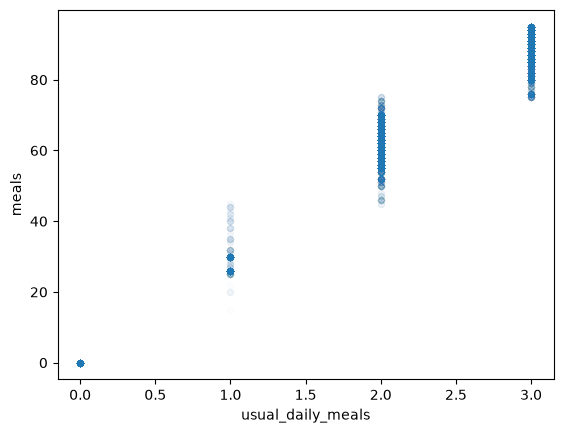

In [34]:
household_members.plot(kind="scatter", x="usual_daily_meals", y="meals", alpha=0.01)

In [35]:
household_meals = household_members.groupby(
    "common_id"
).meals_at_home_last_30_days.sum()
household_meals

common_id
HCES20242230023434102320110133231  101    347.0
HCES20242230023434102320110133231  201    350.0
HCES20242230023434102320110133231  202    180.0
HCES20242230023434102320110133231  203    174.0
HCES20242230023434102320110133231  204    175.0
                                          ...  
HCES2024499991181840623135 118213  314    360.0
HCES2024499991181840623135 118213  315    338.0
HCES2024499991181840623135 118213  316    420.0
HCES2024499991181840623135 118213  317    968.0
HCES2024499991181840623135 118213  318    425.0
Name: meals_at_home_last_30_days, Length: 258537, dtype: float64

In [36]:
consumption = consumption.merge(
    household_meals, on="common_id", validate="1:1", how="left"
)
consumption

,common_id,salt,salt_purchased,salt_non_purchased,proportion_purchased,meals_at_home_last_30_days
0,HCES20242230023434102320110133231 101,1.0,1.0,0.0,1.0,347.0
1,HCES20242230023434102320110133231 201,1.0,1.0,0.0,1.0,350.0
2,HCES20242230023434102320110133231 202,0.5,0.5,0.0,1.0,180.0
3,HCES20242230023434102320110133231 203,0.5,0.5,0.0,1.0,174.0
4,HCES20242230023434102320110133231 204,0.5,0.5,0.0,1.0,175.0
...,...,...,...,...,...,...
261948,HCES2024499991181840623135 118213 314,1.5,1.5,0.0,1.0,360.0
261949,HCES2024499991181840623135 118213 315,1.5,1.5,0.0,1.0,338.0
261950,HCES2024499991181840623135 118213 316,1.5,1.5,0.0,1.0,420.0
261951,HCES2024499991181840623135 118213 317,3.0,3.0,0.0,1.0,968.0


In [37]:
consumption.isnull().mean()

common_id                     0.000000
salt                          0.000000
salt_purchased                0.000000
salt_non_purchased            0.000000
proportion_purchased          0.000000
meals_at_home_last_30_days    0.013041
dtype: float64

In [38]:
consumption = consumption.dropna(how="any").copy()
consumption

,common_id,salt,salt_purchased,salt_non_purchased,proportion_purchased,meals_at_home_last_30_days
0,HCES20242230023434102320110133231 101,1.0,1.0,0.0,1.0,347.0
1,HCES20242230023434102320110133231 201,1.0,1.0,0.0,1.0,350.0
2,HCES20242230023434102320110133231 202,0.5,0.5,0.0,1.0,180.0
3,HCES20242230023434102320110133231 203,0.5,0.5,0.0,1.0,174.0
4,HCES20242230023434102320110133231 204,0.5,0.5,0.0,1.0,175.0
...,...,...,...,...,...,...
261948,HCES2024499991181840623135 118213 314,1.5,1.5,0.0,1.0,360.0
261949,HCES2024499991181840623135 118213 315,1.5,1.5,0.0,1.0,338.0
261950,HCES2024499991181840623135 118213 316,1.5,1.5,0.0,1.0,420.0
261951,HCES2024499991181840623135 118213 317,3.0,3.0,0.0,1.0,968.0


In [39]:
consumption["salt_per_meal_kg"] = np.where(
    consumption.salt == 0,
    0.0,
    consumption.salt / consumption.meals_at_home_last_30_days,
)

In [40]:
# In a small number of cases, salt consumption is reported despite very few or no meals at home
impossible_salt_consumption = (consumption.salt > 0) & (
    consumption.meals_at_home_last_30_days == 0
)
consumption[impossible_salt_consumption]

,common_id,salt,salt_purchased,salt_non_purchased,proportion_purchased,meals_at_home_last_30_days,salt_per_meal_kg
647,HCES2024223462343410122015 128211 301,0.015,0.0,0.015,0.0,0.0,inf
650,HCES2024223462343410122015 128211 304,0.015,0.0,0.015,0.0,0.0,inf
651,HCES2024223462343410122015 128211 305,0.015,0.0,0.015,0.0,0.0,inf
652,HCES2024223462343410122015 128211 306,0.100,0.0,0.100,0.0,0.0,inf
653,HCES2024223462343410122015 128211 307,0.015,0.0,0.015,0.0,0.0,inf
...,...,...,...,...,...,...,...
234819,HCES2024484291282820823147 228143 314,0.200,0.2,0.000,1.0,0.0,inf
235470,HCES2024484661282820723164 128122 313,0.200,0.2,0.000,1.0,0.0,inf
237378,HCES2024485861272742923276 127425 301,0.100,0.1,0.000,1.0,0.0,inf
240156,HCES20244874212727132230110227401 304,0.200,0.2,0.000,1.0,0.0,inf


In [41]:
# This must be wrong somehow, so we clip it
consumption["salt_per_meal_kg"] = consumption["salt_per_meal_kg"].clip(
    upper=np.percentile(consumption.salt_per_meal_kg, 95)
)

<Axes: >

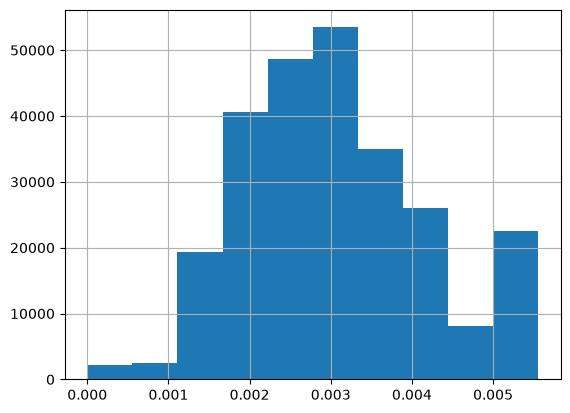

In [42]:
consumption[consumption.salt_per_meal_kg.notnull()].sort_values("salt_per_meal_kg")
consumption.salt_per_meal_kg.hist()

In [43]:
household_members = household_members.merge(
    consumption.reset_index()[
        [
            "common_id",
            "salt_per_meal_kg",
            "proportion_purchased",
        ]
    ],
    on="common_id",
    how="left",
    validate="m:1",
)
household_members

,common_id,gender,age_years,multiplier,usual_daily_meals,meals_from_school_balwadi_last_30_days,meals_from_employer_last_30_days,meals_others_last_30_days,meals_paid_last_30_days,meals_at_home_last_30_days,wealth_quintile,sex,age_start,age_end,meals,salt_per_meal_kg,proportion_purchased
0,HCES2024403761323210523021 132102 201,Male,58,153083,3.0,0.0,0.0,3.0,0.0,87.0,5,Male,50,125,90.0,0.001302,1.0
1,HCES2024403761323210523021 132102 201,Female,47,153083,3.0,0.0,0.0,2.0,0.0,88.0,5,Female,30,50,90.0,0.001302,1.0
2,HCES2024403761323210523021 132102 201,Male,17,153083,3.0,0.0,0.0,2.0,0.0,88.0,5,Male,15,30,90.0,0.001302,1.0
3,HCES2024403761323210523021 132102 201,Female,26,153083,3.0,0.0,0.0,0.0,0.0,90.0,5,Female,15,30,90.0,0.001302,1.0
4,HCES2024403761323210523021 132102 201,Male,45,153083,3.0,0.0,0.0,6.0,0.0,84.0,5,Male,30,50,90.0,0.001302,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1099472,HCES2024432771101011923356 2101116 317,Male,20,157235,2.0,0.0,0.0,0.0,8.0,52.0,3,Male,15,30,60.0,0.001420,1.0
1099473,HCES2024432771101011923356 2101116 317,Male,18,157235,3.0,0.0,0.0,0.0,0.0,90.0,3,Male,15,30,90.0,0.001420,1.0
1099474,HCES2024432771101011923356 2101116 317,Male,16,157235,3.0,0.0,0.0,0.0,0.0,90.0,3,Male,15,30,90.0,0.001420,1.0
1099475,HCES2024432771101011923356 2101116 318,Male,25,157235,2.0,0.0,0.0,0.0,0.0,60.0,1,Male,15,30,60.0,0.004167,1.0


In [44]:
household_members.isnull().mean()

common_id                                 0.000000
gender                                    0.000000
age_years                                 0.000000
multiplier                                0.000000
usual_daily_meals                         0.000000
meals_from_school_balwadi_last_30_days    0.000000
meals_from_employer_last_30_days          0.000000
meals_others_last_30_days                 0.000000
meals_paid_last_30_days                   0.000000
meals_at_home_last_30_days                0.000000
wealth_quintile                           0.000000
sex                                       0.000193
age_start                                 0.000000
age_end                                   0.000000
meals                                     0.000000
salt_per_meal_kg                          0.000000
proportion_purchased                      0.000000
dtype: float64

In [45]:
household_members["salt"] = household_members.meals * household_members.salt_per_meal_kg
assert (household_members.meals >= household_members.meals_at_home_last_30_days).all()

In [46]:
household_members.isnull().mean()

common_id                                 0.000000
gender                                    0.000000
age_years                                 0.000000
multiplier                                0.000000
usual_daily_meals                         0.000000
meals_from_school_balwadi_last_30_days    0.000000
meals_from_employer_last_30_days          0.000000
meals_others_last_30_days                 0.000000
meals_paid_last_30_days                   0.000000
meals_at_home_last_30_days                0.000000
wealth_quintile                           0.000000
sex                                       0.000193
age_start                                 0.000000
age_end                                   0.000000
meals                                     0.000000
salt_per_meal_kg                          0.000000
proportion_purchased                      0.000000
salt                                      0.000000
dtype: float64

In [47]:
# Convert kg/30 days to g/day
household_members["salt_g_per_day"] = household_members.salt / 30 * 1_000

In [48]:
def save_data(series, name):
    hces_utils.save_data(series, name, vehicle="salt")

In [49]:
weighted_avg_and_std(
    household_members.salt_g_per_day > 0, weights=household_members.multiplier
)

mean                          0.989640
sd                            0.101257
effective_sample_size    757012.583701
dtype: float64

In [50]:
weighted_summary(
    household_members, lambda df: df.salt_g_per_day > 0, by="wealth_quintile"
)

,mean,sd,effective_sample_size
wealth_quintile,,,
1,0.984977,0.121646,161777.795702
2,0.984782,0.122419,154018.083482
3,0.992166,0.088163,164731.050610
4,0.993357,0.081233,138151.620870
5,0.993078,0.082912,139952.971220


In [51]:
# NOTE: We do not have pregnancy status in this survey, so we assume it has no effect on consumption!
any_consumption = weighted_summary(
    household_members,
    lambda df: np.where(df.salt_g_per_day.notnull(), df.salt_g_per_day > 0, np.nan),
)
any_consumption

mean        sd  \
sex    age_start age_end wealth_quintile                       
Female 0         5       1                0.902333  0.296864   
                         2                0.890204  0.312636   
                         3                0.883991  0.320235   
                         4                0.891527  0.310976   
                         5                0.873610  0.332288   
       5         15      1                0.974985  0.156171   
                         2                0.996484  0.059194   
                         3                1.000000  0.000000   
                         4                1.000000  0.000000   
                         5                1.000000  0.000000   
       15        30      1                0.988071  0.108566   
                         2                0.986670  0.114685   
                         3                0.998649  0.036731   
                         4                0.999695  0.017450   
                         5                1.000000  0.000000   
       30        50      1                0.999892  0.010409   
                         2                0.999702  0.017264   
                         3                0.999976  0.004915   
                         4                0.999998  0.001532   
                         5                0.999973  0.005218   
       50        125     1                0.999124  0.029591   
                         2                0.998569  0.037805   
                         3                0.999309  0.026271   
                         4                0.999807  0.013900   
                         5                0.999944  0.007478   
Male   0         5       1                0.906283  0.291434   
                         2                0.888263  0.315043   
                         3                0.889505  0.313506   
                         4                0.889035  0.314089   
                         5                0.882098  0.322492   
       5         15      1                0.986465  0.115551   
                         2                0.996389  0.059987   
                         3                1.000000  0.000000   
                         4                1.000000  0.000000   
                         5                1.000000  0.000000   
       15        30      1                0.987804  0.109761   
                         2                0.975987  0.153089   
                         3                0.997971  0.045003   
                         4                0.999731  0.016396   
                         5                0.999922  0.008817   
       30        50      1                0.999192  0.028417   
                         2                0.994653  0.072926   
                         3                0.999500  0.022345   
                         4                0.999797  0.014230   
                         5                0.999932  0.008252   
       50        125     1                0.999263  0.027137   
                         2                0.997723  0.047664   
                         3                0.999551  0.021190   
                         4                0.999518  0.021952   
                         5                0.999925  0.008679   

                                          effective_sample_size  
sex    age_start age_end wealth_quintile                         
Female 0         5       1                          6268.530724  
                         2                          5497.291178  
                         3                          4966.636820  
                         4                          3801.162571  
                         5                          3789.443714  
       5         15      1                         16295.633358  
                         2                         14029.643687  
                         3                         13023.610898  
                         4                         10253.

In [52]:
save_data(any_consumption["mean"], "salt/vehicle_consumption/any")

In [53]:
weighted_avg_and_std(
    household_members.salt_g_per_day, weights=household_members.multiplier
)

mean                          7.162902
sd                            2.698575
effective_sample_size    757012.583701
dtype: float64

In [54]:
weighted_summary(household_members, lambda df: df.salt_g_per_day, by="wealth_quintile")

,mean,sd,effective_sample_size
wealth_quintile,,,
1,7.412659,2.874974,161777.795702
2,7.208034,2.807752,154018.083482
3,7.125894,2.676113,164731.050610
4,7.122045,2.618453,138151.620870
5,6.941132,2.468294,139952.971220


In [55]:
consumption_amount = weighted_summary(household_members, lambda df: df.salt_g_per_day)
consumption_amount

mean        sd  \
sex    age_start age_end wealth_quintile                       
Female 0         5       1                6.746382  3.438780   
                         2                6.567474  3.452668   
                         3                6.225485  3.282116   
                         4                6.274136  3.208261   
                         5                6.208263  3.262381   
       5         15      1                7.571986  2.919715   
                         2                7.566951  2.653035   
                         3                7.377030  2.502145   
                         4                7.356090  2.543315   
                         5                7.261472  2.355980   
       15        30      1                7.209870  2.787171   
                         2                6.991849  2.732437   
                         3                6.958188  2.540537   
                         4                7.051616  2.497103   
                         5                6.919556  2.359356   
       30        50      1                7.393107  2.744791   
                         2                7.158507  2.652026   
                         3                7.167685  2.641539   
                         4                7.154002  2.581271   
                         5                6.877392  2.404004   
       50        125     1                7.629817  2.885465   
                         2                7.265818  2.743672   
                         3                7.282494  2.770341   
                         4                7.108371  2.632679   
                         5                6.949881  2.496575   
Male   0         5       1                6.786021  3.427112   
                         2                6.618497  3.464105   
                         3                6.280267  3.292364   
                         4                6.274438  3.285870   
                         5                6.236960  3.217131   
       5         15      1                7.779073  2.818141   
                         2                7.702890  2.698701   
                         3                7.430335  2.539820   
                         4                7.403600  2.531187   
                         5                7.246037  2.331509   
       15        30      1                7.389201  2.779912   
                         2                7.210724  2.893672   
                         3                7.171653  2.585632   
                         4                7.220573  2.505998   
                         5                7.071103  2.349376   
       30        50      1                7.326526  2.753154   
                         2                7.126703  2.729265   
                         3                7.067732  2.623826   
                         4                7.066580  2.569775   
                         5                6.807658  2.368254   
       50        125     1                7.587179  2.836423   
                         2                7.269679  2.717756   
                         3                7.214675  2.687427   
                         4                7.213035  2.634700   
                         5                7.046214  2.513367   

                                          effective_sample_size  
sex    age_start age_end wealth_quintile                         
Female 0         5       1                          6268.530724  
                         2                          5497.291178  
                         3                          4966.636820  
                         4                          3801.162571  
                         5                          3789.443714  
       5         15      1                         16295.633358  
                         2                         14029.643687  
                         3                         13023.610898  
                         4                         10253.

In [56]:
save_data(consumption_amount["mean"], "salt/vehicle_consumption/amount/mean")
save_data(consumption_amount["sd"], "salt/vehicle_consumption/amount/sd")

In [57]:
weighted_summary(
    household_members,
    lambda df: df.proportion_purchased,
    weights=lambda df: df.multiplier * df.salt,
    by="wealth_quintile",
)

,mean,sd,effective_sample_size
wealth_quintile,,,
1,0.999589,0.020260,140121.328546
2,0.999697,0.017283,133931.803036
3,0.999677,0.017980,144559.198457
4,0.999865,0.011603,122600.712161
5,0.999920,0.008966,123251.659469


In [58]:
proportion_purchased = weighted_summary(
    household_members,
    lambda df: df.proportion_purchased,
    weights=lambda df: df.multiplier * df.salt,
)
proportion_purchased

mean        sd  \
sex    age_start age_end wealth_quintile                       
Female 0         5       1                0.999676  0.018011   
                         2                0.999348  0.024372   
                         3                0.999553  0.021148   
                         4                1.000000  0.000000   
                         5                1.000000  0.000000   
       5         15      1                0.998848  0.033921   
                         2                0.999931  0.008301   
                         3                0.999567  0.020796   
                         4                0.999932  0.008239   
                         5                0.999823  0.013300   
       15        30      1                0.999573  0.020654   
                         2                0.999596  0.019991   
                         3                0.999831  0.012995   
                         4                0.999887  0.010652   
                         5                0.999937  0.007933   
       30        50      1                0.999844  0.012503   
                         2                0.999837  0.012773   
                         3                0.999631  0.019209   
                         4                0.999922  0.008860   
                         5                0.999890  0.010481   
       50        125     1                0.999261  0.027181   
                         2                0.999449  0.023461   
                         3                0.999358  0.025339   
                         4                0.999871  0.011350   
                         5                0.999938  0.007862   
Male   0         5       1                0.999835  0.012844   
                         2                0.999439  0.023131   
                         3                0.999862  0.011738   
                         4                1.000000  0.000000   
                         5                0.999699  0.017356   
       5         15      1                0.999822  0.013325   
                         2                0.999946  0.007373   
                         3                0.999776  0.014949   
                         4                0.999763  0.015392   
                         5                0.999918  0.009071   
       15        30      1                0.999806  0.013945   
                         2                0.999622  0.019324   
                         3                0.999843  0.012527   
                         4                0.999806  0.013933   
                         5                0.999943  0.007554   
       30        50      1                0.999835  0.012830   
                         2                0.999891  0.010436   
                         3                0.999589  0.020261   
                         4                0.999819  0.013436   
                         5                0.999937  0.007960   
       50        125     1                0.999381  0.024869   
                         2                0.999452  0.023405   
                         3                0.999751  0.015788   
                         4                0.999862  0.011749   
                         5                0.999958  0.006444   

                                          effective_sample_size  
sex    age_start age_end wealth_quintile                         
Female 0         5       1                          4920.798235  
                         2                          4294.110512  
                         3                          3900.068232  
                         4                          3034.616174  
                         5                          2835.132206  
       5         15      1                         14369.024253  
                         2                         12454.184814  
                         3                         11823.959650  
                         4                          9180.

In [59]:
proportion_purchased["mean"].rename("value").to_csv(
    "india_salt_proportion_purchased.csv"
)